In [21]:
import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [22]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shahliza27/ur-fall-detection-dataset")

print("Path to dataset files:", path)

DATASET_ROOT = Path(path)

Using Colab cache for faster access to the 'ur-fall-detection-dataset' dataset.
Path to dataset files: /kaggle/input/ur-fall-detection-dataset


In [23]:
print("Dataset root:", DATASET_ROOT)

for root, dirs, files in os.walk(DATASET_ROOT):
    relative = Path(root).relative_to(DATASET_ROOT)
    depth = len(relative.parts)
    indent = "  " * depth

    print(f"{indent}{Path(root).name}/")

    for f in files[:8]:
        print(f"{indent}  {f}")

    if len(files) > 8:
        print(f"{indent}  ... ({len(files)} files)")

Dataset root: /kaggle/input/ur-fall-detection-dataset
ur-fall-detection-dataset/
  UR_fall_detection_dataset_cam0_rgb/
    adl-07-cam0-rgb/
      adl-07-cam0-rgb-057.png
      adl-07-cam0-rgb-034.png
      adl-07-cam0-rgb-178.png
      adl-07-cam0-rgb-126.png
      adl-07-cam0-rgb-002.png
      adl-07-cam0-rgb-103.png
      adl-07-cam0-rgb-153.png
      adl-07-cam0-rgb-174.png
      ... (180 files)
    adl-32-cam0-rgb/
      adl-32-cam0-rgb-042.png
      adl-32-cam0-rgb-015.png
      adl-32-cam0-rgb-039.png
      adl-32-cam0-rgb-102.png
      adl-32-cam0-rgb-117.png
      adl-32-cam0-rgb-189.png
      adl-32-cam0-rgb-009.png
      adl-32-cam0-rgb-057.png
      ... (200 files)
    adl-28-cam0-rgb/
      adl-28-cam0-rgb-043.png
      adl-28-cam0-rgb-055.png
      adl-28-cam0-rgb-028.png
      adl-28-cam0-rgb-050.png
      adl-28-cam0-rgb-030.png
      adl-28-cam0-rgb-040.png
      adl-28-cam0-rgb-031.png
      adl-28-cam0-rgb-083.png
      ... (85 files)
    fall-29-cam0-rgb/
      fall-

In [24]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

sequence_dirs = []

for directory in DATASET_ROOT.rglob("*"):
    if not directory.is_dir():
        continue

    image_files = [
        p for p in directory.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if image_files:
        sequence_dirs.append(directory)

print("Image-sequence folders found:", len(sequence_dirs))

# Show examples
for d in sequence_dirs[:20]:
    n_images = sum(
        1 for p in d.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{d.name:35s} -> {n_images} frames")

Image-sequence folders found: 70
adl-07-cam0-rgb                     -> 180 frames
adl-32-cam0-rgb                     -> 200 frames
adl-28-cam0-rgb                     -> 85 frames
fall-29-cam0-rgb                    -> 99 frames
fall-24-cam0-rgb                    -> 60 frames
fall-07-cam0-rgb                    -> 156 frames
fall-16-cam0-rgb                    -> 55 frames
adl-02-cam0-rgb                     -> 180 frames
adl-35-cam0-rgb                     -> 280 frames
fall-11-cam0-rgb                    -> 130 frames
fall-18-cam0-rgb                    -> 65 frames
fall-06-cam0-rgb                    -> 100 frames
fall-15-cam0-rgb                    -> 71 frames
adl-20-cam0-rgb                     -> 270 frames
fall-28-cam0-rgb                    -> 66 frames
adl-31-cam0-rgb                     -> 250 frames
adl-24-cam0-rgb                     -> 70 frames
adl-18-cam0-rgb                     -> 265 frames
adl-38-cam0-rgb                     -> 345 frames
adl-40-cam0-rgb          

In [25]:
def sequence_label(folder_name):
    name = folder_name.lower()

    if name.startswith("fall-") or name.startswith("fall_"):
        return 1
    if name.startswith("adl-") or name.startswith("adl_"):
        return 0

    if re.search(r"(^|[_-])fall([_-]|$)", name):
        return 1
    if re.search(r"(^|[_-])adl([_-]|$)", name):
        return 0

    return None

records = []

for sequence_dir in sequence_dirs:
    label = sequence_label(sequence_dir.name)

    if label is not None:
        frame_paths = sorted([
            p for p in sequence_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        records.append({
            "sequence_id": sequence_dir.name,
            "sequence_dir": str(sequence_dir),
            "label": label,
            "num_frames": len(frame_paths)
        })

sequences = pd.DataFrame(records)

print("Total labeled sequences:", len(sequences))
print("\nClass distribution:")
print(sequences["label"].map({0: "ADL / Normal", 1: "Fall"}).value_counts())

display(sequences.head(10))

Total labeled sequences: 70

Class distribution:
label
ADL / Normal    40
Fall            30
Name: count, dtype: int64


,sequence_id,sequence_dir,label,num_frames
0,adl-07-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,0,180
1,adl-32-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,0,200
2,adl-28-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,0,85
3,fall-29-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,1,99
4,fall-24-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,1,60
5,fall-07-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,1,156
6,fall-16-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,1,55
7,adl-02-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,0,180
8,adl-35-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,0,280
9,fall-11-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,1,130


Frames per sequence:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,40.0,223.525000,78.958602,70.0,180.0,232.5,271.25,400.0
1,30.0,99.833333,40.640631,55.0,67.0,93.5,110.00,215.0


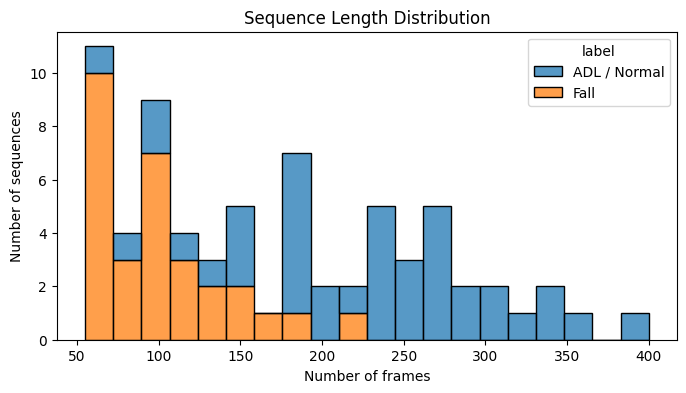

In [26]:
print("Frames per sequence:")
display(sequences.groupby("label")["num_frames"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(
    data=sequences,
    x="num_frames",
    hue=sequences["label"].map({0: "ADL / Normal", 1: "Fall"}),
    bins=20,
    multiple="stack"
)
plt.xlabel("Number of frames")
plt.ylabel("Number of sequences")
plt.title("Sequence Length Distribution")
plt.show()

In [27]:
def get_frame_paths(sequence_dir):
    directory = Path(sequence_dir)
    return sorted([
        p for p in directory.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

def check_sequence(sequence_dir):
    frame_paths = get_frame_paths(sequence_dir)

    if len(frame_paths) == 0:
        return False, 0

    valid = 0
    for p in frame_paths:
        try:
            with Image.open(p) as img:
                img.verify()
            valid += 1
        except Exception:
            pass

    return valid == len(frame_paths), valid

verification = []

for _, row in tqdm(sequences.iterrows(), total=len(sequences), desc="Checking sequences"):
    ok, valid_count = check_sequence(row["sequence_dir"])
    verification.append((ok, valid_count))

sequences["all_frames_readable"] = [x[0] for x in verification]
sequences["valid_frames"] = [x[1] for x in verification]

print("Sequences with unreadable/corrupt frames:",
      int((~sequences["all_frames_readable"]).sum()))

display(sequences[~sequences["all_frames_readable"]].head())

Checking sequences:   0%|          | 0/70 [00:00<?, ?it/s]

Sequences with unreadable/corrupt frames: 0


,sequence_id,sequence_dir,label,num_frames,all_frames_readable,valid_frames


In [28]:
sequences = sequences[sequences["all_frames_readable"]].copy()

print("Usable sequences:", len(sequences))
print("Fall sequences:", int((sequences.label == 1).sum()))
print("ADL sequences :", int((sequences.label == 0).sum()))

Usable sequences: 70
Fall sequences: 30
ADL sequences : 40


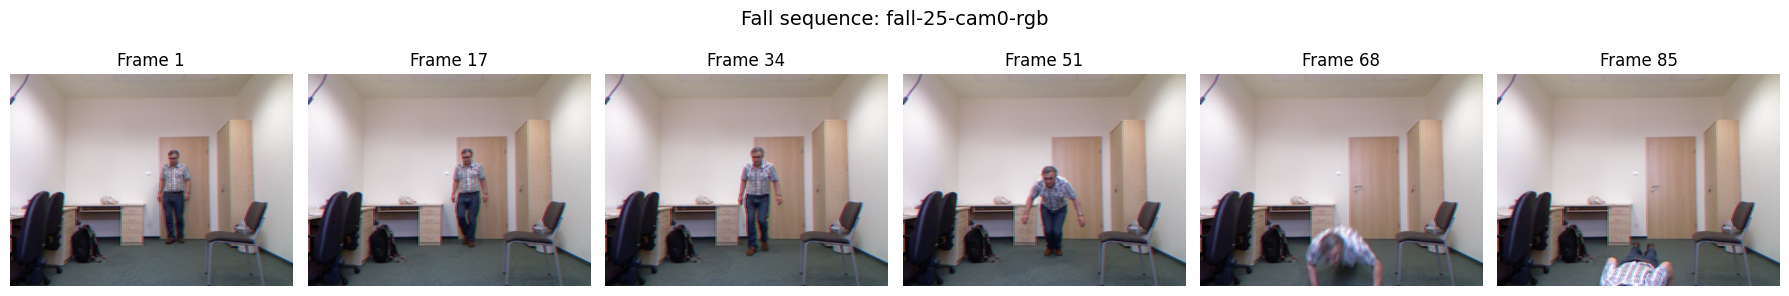

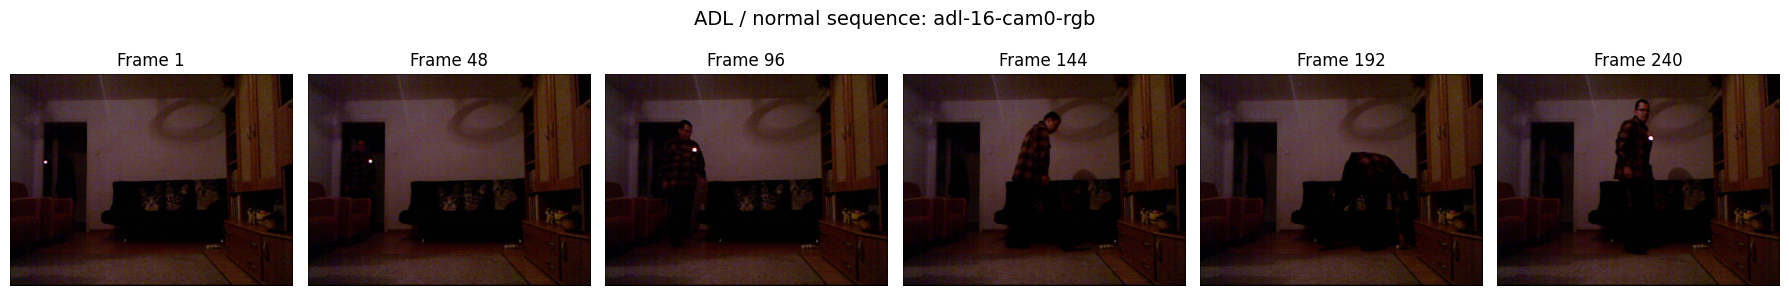

In [29]:
def temporal_indices(total_frames, n=6):
    if total_frames <= 0:
        return np.zeros(n, dtype=int)
    return np.linspace(0, total_frames - 1, n).astype(int)

def read_rgb_frame(path):
    with Image.open(path) as img:
        return np.array(img.convert("RGB"))

def show_sequence(sequence_dir, title="", n_frames=6):
    frame_paths = get_frame_paths(sequence_dir)
    indices = temporal_indices(len(frame_paths), n_frames)

    fig, axes = plt.subplots(1, n_frames, figsize=(18, 3.2))

    if n_frames == 1:
        axes = [axes]

    for ax, idx in zip(axes, indices):
        frame = read_rgb_frame(frame_paths[idx])
        ax.imshow(frame)
        ax.set_title(f"Frame {idx + 1}")
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

fall_example = sequences[sequences.label == 1].sample(1, random_state=SEED).iloc[0]
adl_example = sequences[sequences.label == 0].sample(1, random_state=SEED).iloc[0]

show_sequence(
    fall_example.sequence_dir,
    title=f"Fall sequence: {fall_example.sequence_id}"
)

show_sequence(
    adl_example.sequence_dir,
    title=f"ADL / normal sequence: {adl_example.sequence_id}"
)

In [30]:
NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112
CHANNELS = 3

BATCH_SIZE = 4
EPOCHS = 10

INPUT_SHAPE = (NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, CHANNELS)

print("Input tensor shape:", INPUT_SHAPE)

Input tensor shape: (16, 112, 112, 3)


In [31]:
def sample_frame_paths(frame_paths, num_frames=NUM_FRAMES, training=False):
    n = len(frame_paths)

    if n == 0:
        raise ValueError("Sequence contains no image frames.")

    if n >= num_frames:
        edges = np.linspace(0, n, num_frames + 1)

        indices = []

        for i in range(num_frames):
            start = int(np.floor(edges[i]))
            end = int(np.floor(edges[i + 1]))

            end = max(end, start + 1)
            end = min(end, n)

            if training:
                idx = np.random.randint(start, end)
            else:
                idx = (start + end - 1) // 2

            indices.append(idx)

        return [frame_paths[i] for i in indices]

    indices = np.resize(np.arange(n), num_frames)
    return [frame_paths[i] for i in indices]

def load_sequence(sequence_dir, training=False):
    frame_paths = get_frame_paths(sequence_dir)
    selected_paths = sample_frame_paths(
        frame_paths,
        NUM_FRAMES,
        training=training
    )

    frames = []

    for path in selected_paths:
        frame = read_rgb_frame(path)

        # Resize to 112x112
        frame = tf.image.resize(
            frame,
            [IMG_HEIGHT, IMG_WIDTH],
            method="bilinear"
        )

        frame = tf.cast(frame, tf.float32) / 255.0

        frames.append(frame)

    return tf.stack(frames, axis=0)

example_tensor = load_sequence(
    fall_example.sequence_dir,
    training=False
)

print("Tensor shape:", example_tensor.shape)
print("Minimum:", float(tf.reduce_min(example_tensor)))
print("Maximum:", float(tf.reduce_max(example_tensor)))

Tensor shape: (16, 112, 112, 3)
Minimum: 0.0
Maximum: 1.0


In [32]:
train_df, temp_df = train_test_split(
    sequences,
    test_size=0.30,
    stratify=sequences["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print(f"Train: {len(train_df)} sequences")
print(f"Validation: {len(val_df)} sequences")
print(f"Test: {len(test_df)} sequences")

print("\nClass distribution:")
print("Train:", train_df["label"].value_counts().sort_index().to_dict())
print("Val  :", val_df["label"].value_counts().sort_index().to_dict())
print("Test :", test_df["label"].value_counts().sort_index().to_dict())

Train: 49 sequences
Validation: 10 sequences
Test: 11 sequences

Class distribution:
Train: {0: 28, 1: 21}
Val  : {0: 6, 1: 4}
Test : {0: 6, 1: 5}


In [33]:
def augment_sequence(video):
    # Random horizontal flipping
    if tf.random.uniform(()) < 0.5:
        video = tf.image.flip_left_right(video)

    # Random crop followed by resize
    if tf.random.uniform(()) < 0.5:
        crop_h = int(IMG_HEIGHT * 0.90)
        crop_w = int(IMG_WIDTH * 0.90)

        video = tf.image.random_crop(
            video,
            size=[NUM_FRAMES, crop_h, crop_w, CHANNELS]
        )

        video = tf.image.resize(
            video,
            [IMG_HEIGHT, IMG_WIDTH]
        )


    if tf.random.uniform(()) < 0.5:
        shift = tf.random.uniform(
            [],
            minval=0,
            maxval=NUM_FRAMES,
            dtype=tf.int32
        )
        video = tf.roll(video, shift=shift, axis=0)

    return tf.clip_by_value(video, 0.0, 1.0)

def sequence_generator(frame_df, training=False):
    rows = frame_df[["sequence_dir", "label"]].to_dict("records")

    order = np.arange(len(rows))

    if training:
        np.random.shuffle(order)

    for i in order:
        row = rows[i]

        video = load_sequence(
            row["sequence_dir"],
            training=training
        )

        if training:
            video = augment_sequence(video)

        yield video, np.float32(row["label"])

output_signature = (
    tf.TensorSpec(
        shape=INPUT_SHAPE,
        dtype=tf.float32
    ),
    tf.TensorSpec(
        shape=(),
        dtype=tf.float32
    )
)

train_ds = tf.data.Dataset.from_generator(
    lambda: sequence_generator(train_df, training=True),
    output_signature=output_signature
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_generator(
    lambda: sequence_generator(val_df, training=False),
    output_signature=output_signature
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_generator(
    lambda: sequence_generator(test_df, training=False),
    output_signature=output_signature
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [34]:
class_counts = train_df["label"].value_counts().sort_index()

total = len(train_df)
num_classes = 2

class_weight = {
    int(cls): total / (num_classes * count)
    for cls, count in class_counts.items()
}

print("Training class counts:", class_counts.to_dict())
print("Class weights:", class_weight)

Training class counts: {0: 28, 1: 21}
Class weights: {0: 0.875, 1: 1.1666666666666667}


In [35]:
def build_3d_cnn():
    inputs = keras.Input(shape=INPUT_SHAPE)

    x = layers.Conv3D(
        32,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool3D(pool_size=(1, 2, 2))(x)

    x = layers.Conv3D(
        64,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool3D(pool_size=(2, 2, 2))(x)

    x = layers.Conv3D(
        128,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool3D(pool_size=(2, 2, 2))(x)

    x = layers.Conv3D(
        256,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.GlobalAveragePooling3D()(x)

    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="URFD_3D_CNN"
    )

model = build_3d_cnn()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "URFD_3D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 16, 112, 112,   │         2,624 │
│                                 │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 112, 112,   │           128 │
│ (BatchNormalization)            │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 16, 56, 56, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 16, 56, 56, 64) │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 56, 56, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 8, 28, 28, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_6 (Conv3D)               │ (None, 8, 28, 28, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 8, 28, 28, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 4, 14, 14, 128) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_7 (Conv3D)               │ (None, 4, 14, 14, 256) │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 4, 14, 14, 256) │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,233 (4.57 MB)

 Trainable params: 1,198,273 (4.57 MB)

 Non-trainable params: 960 (3.75 KB)

In [36]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/10
     13/Unknown 40s 2s/step - accuracy: 0.6490 - auc: 0.6294 - loss: 0.6379 - precision: 0.5649 - recall: 0.9963

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


13/13 ━━━━━━━━━━━━━━━━━━━━ 48s 3s/step - accuracy: 0.6939 - auc: 0.7687 - loss: 0.6130 - precision: 0.5882 - recall: 0.9524 - val_accuracy: 0.6000 - val_auc: 0.9167 - val_loss: 0.6833 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/10


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7930 - auc: 0.8281 - loss: 0.5482 - precision: 0.7197 - recall: 0.8512

...

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8217 - auc: 0.9335 - loss: 0.3852 - precision: 0.7279 - recall: 0.9888

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8367 - auc: 0.9303 - loss: 0.3963 - precision: 0.7407 - recall: 0.9524 - val_accuracy: 0.6000 - val_auc: 0.7708 - val_loss: 0.7514 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 5.0000e-05


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


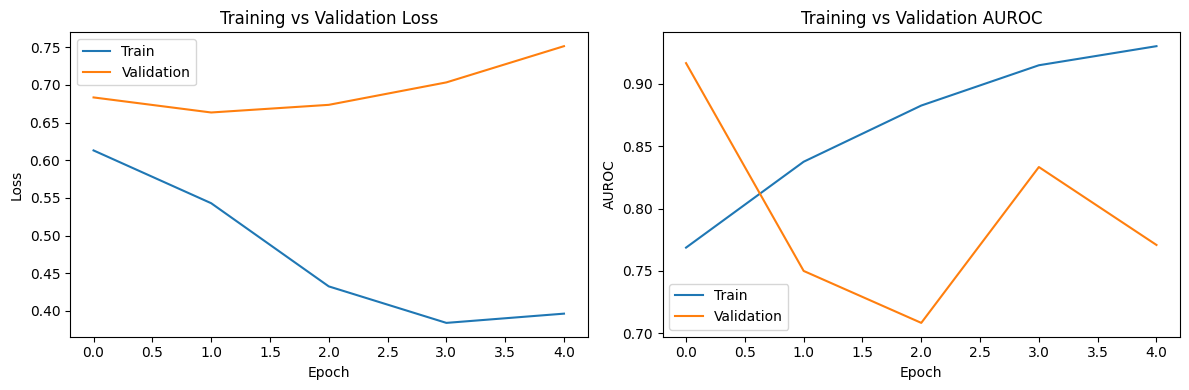

In [37]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["loss"], label="Train")
axes[0].plot(history_df["val_loss"], label="Validation")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_df["auc"], label="Train")
axes[1].plot(history_df["val_auc"], label="Validation")
axes[1].set_title("Training vs Validation AUROC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUROC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [38]:
test_metrics = model.evaluate(test_ds, verbose=1)

for name, value in zip(model.metrics_names, test_metrics):
    print(f"{name}: {value:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.6364 - auc: 0.9667 - loss: 0.6819 - precision: 0.5556 - recall: 1.0000
loss: 0.6819
compile_metrics: 0.6364


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [39]:
y_true = []
y_prob = []
test_paths = []

for videos, labels in test_ds:
    probs = model.predict(videos, verbose=0).ravel()

    y_prob.extend(probs.tolist())
    y_true.extend(labels.numpy().astype(int).tolist())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auroc = roc_auc_score(y_true, y_prob)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

display(results.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Accuracy,0.6364
1,Precision,0.5556
2,Recall,1.0000
3,F1-score,0.7143
4,AUROC,0.9333


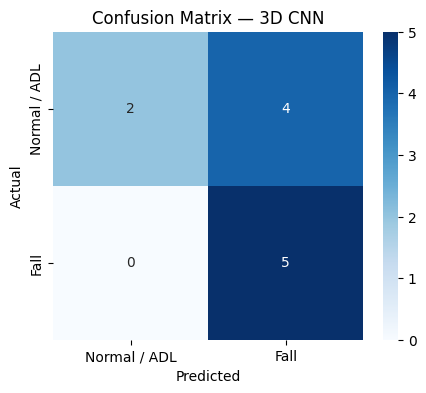

              precision    recall  f1-score   support

Normal / ADL       1.00      0.33      0.50         6
        Fall       0.56      1.00      0.71         5

    accuracy                           0.64        11
   macro avg       0.78      0.67      0.61        11
weighted avg       0.80      0.64      0.60        11



In [40]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal / ADL", "Fall"],
    yticklabels=["Normal / ADL", "Fall"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — 3D CNN")
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal / ADL", "Fall"],
    zero_division=0
))

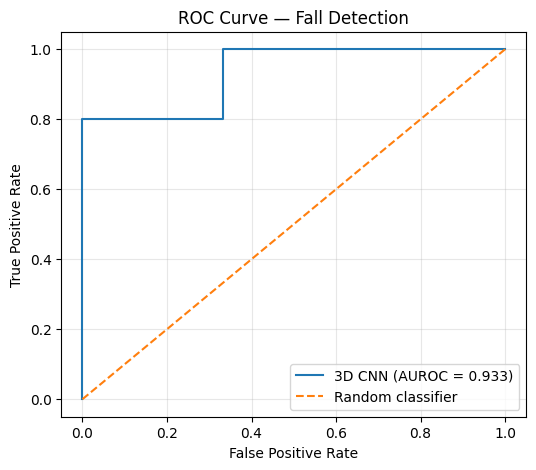

In [41]:
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    label=f"3D CNN (AUROC = {auroc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Fall Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
test_results = test_df.reset_index(drop=True).copy()

test_results["prob_fall"] = y_prob
test_results["pred"] = y_pred
test_results["correct"] = test_results["label"] == test_results["pred"]

errors = test_results[~test_results["correct"]].copy()

print("Test sequences:", len(test_results))
print("Misclassified sequences:", len(errors))

display(
    errors[
        ["sequence_id", "label", "pred", "prob_fall"]
    ].head(20)
)

Test sequences: 11
Misclassified sequences: 4


,sequence_id,label,pred,prob_fall
2,adl-34-cam0-rgb,0,1,0.506936
4,adl-37-cam0-rgb,0,1,0.500864
7,adl-01-cam0-rgb,0,1,0.507380
8,adl-25-cam0-rgb,0,1,0.501965


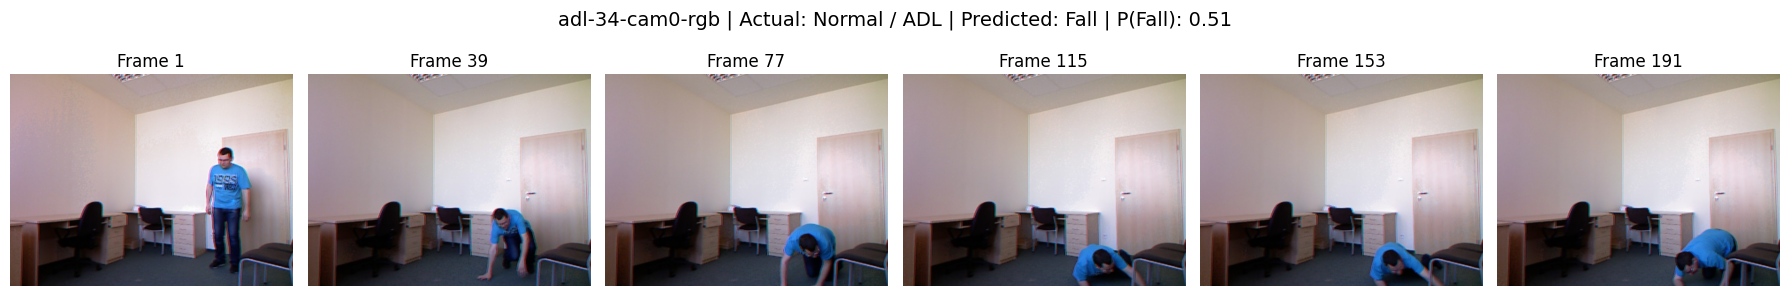

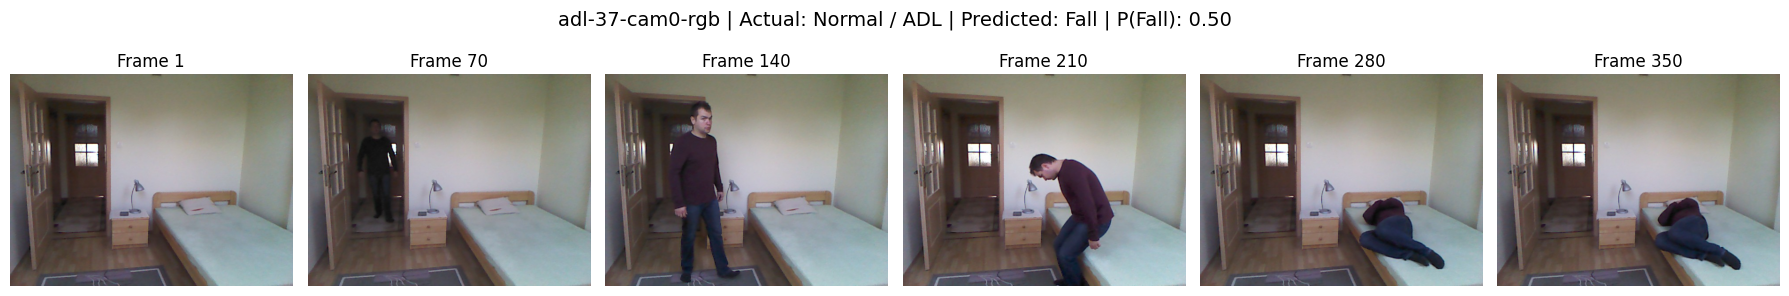

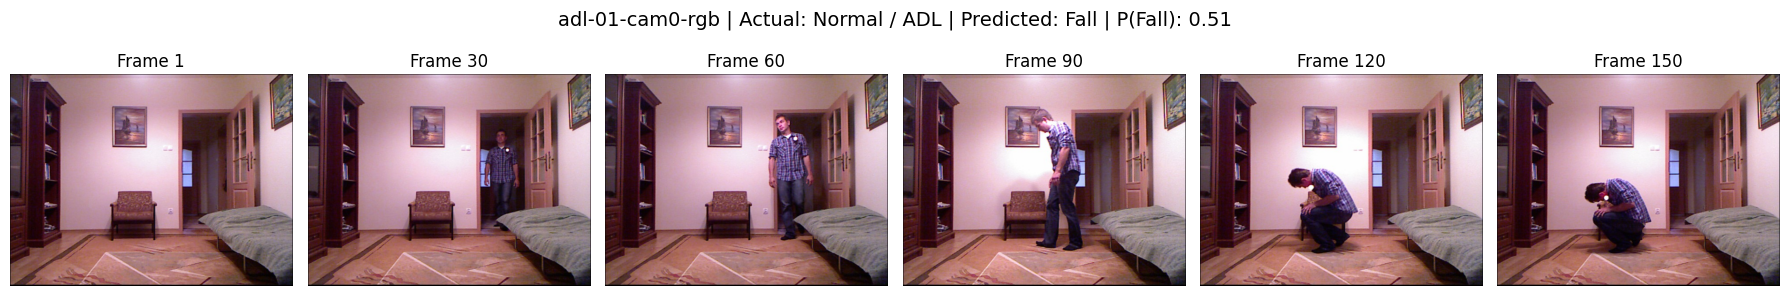

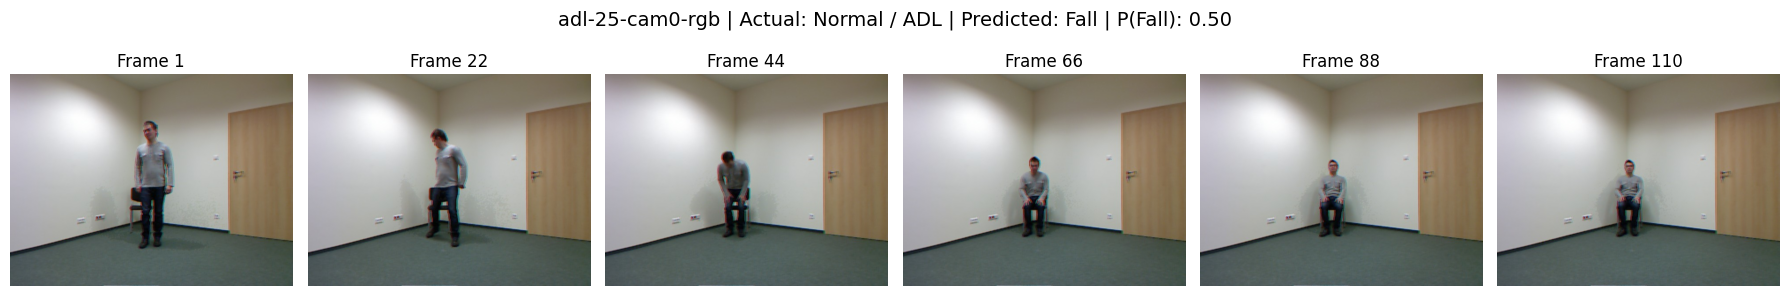

In [43]:
def show_misclassified_sequences(errors, max_sequences=4):
    selected = errors.head(max_sequences)

    if len(selected) == 0:
        print("No misclassified sequences at the 0.5 threshold.")
        return

    for _, row in selected.iterrows():
        actual = "Fall" if row["label"] == 1 else "Normal / ADL"
        predicted = "Fall" if row["pred"] == 1 else "Normal / ADL"

        show_sequence(
            row["sequence_dir"],
            title=(
                f"{row['sequence_id']} | "
                f"Actual: {actual} | "
                f"Predicted: {predicted} | "
                f"P(Fall): {row['prob_fall']:.2f}"
            ),
            n_frames=6
        )

show_misclassified_sequences(errors, max_sequences=4)

In [44]:
test_results["uncertainty"] = np.abs(
    test_results["prob_fall"] - 0.5
)

uncertain = test_results.sort_values("uncertainty").head(10)

display(
    uncertain[
        ["sequence_id", "label", "pred", "prob_fall", "uncertainty"]
    ]
)

,sequence_id,label,pred,prob_fall,uncertainty
4,adl-37-cam0-rgb,0,1,0.500864,0.000864
8,adl-25-cam0-rgb,0,1,0.501965,0.001965
0,adl-40-cam0-rgb,0,0,0.495950,0.004050
9,fall-27-cam0-rgb,1,1,0.506643,0.006643
2,adl-34-cam0-rgb,0,1,0.506936,0.006936
7,adl-01-cam0-rgb,0,1,0.507380,0.007380
3,fall-25-cam0-rgb,1,1,0.508631,0.008631
10,fall-10-cam0-rgb,1,1,0.509092,0.009092
5,fall-06-cam0-rgb,1,1,0.509459,0.009459
6,fall-16-cam0-rgb,1,1,0.509877,0.009877


In [45]:
# Save the trained model
MODEL_PATH = "urfd_3d_cnn_image_sequences.keras"
model.save(MODEL_PATH)

print("Saved model:", MODEL_PATH)

Saved model: urfd_3d_cnn_image_sequences.keras
